# B-8802B · o modelo do Drive × a versão atual do repositório

**Pergunta:** vale atualizar o B-8802B-2025 no Drive?

Para usar os arquivos reais do Drive, troque `DRIVE` na célula abaixo pela pasta baixada do Drive e reexecute. Sem ela,
o notebook usa a versão reconstruída do git (commit b02b7dd, a que subiu para o Drive).

In [1]:
import sys, json, hashlib, importlib.util
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent

DRIVE = RAIZ / "results/drive_vs_atual/drive_reconstruido"      # ← troque pela pasta do Drive
ATUAL_MOD = RAIZ / "deploy_v2/Transpetro/simpred_inference.py"
ATUAL_BUNDLE = RAIZ / "deploy_v2/Transpetro/B-8802B-2025/modelos/model_2025-01-01_2026-08-10_VAE"

def achar(pasta):
    mod = next(pasta.rglob("simpred_inference.py"))
    alarmes = [p.parent for p in pasta.rglob("alarm.json") if "B-8802B-2025" in str(p) or p.parent.parent == pasta]
    return mod, alarmes[0]

def carregar_modulo(nome, caminho):
    spec = importlib.util.spec_from_file_location(nome, caminho)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m

DRIVE_MOD, DRIVE_BUNDLE = achar(DRIVE)
VERSOES = {"Drive": (carregar_modulo("si_drive", DRIVE_MOD), DRIVE_BUNDLE, "#8a897f"),
           "atual (repositório)": (carregar_modulo("si_atual", ATUAL_MOD), ATUAL_BUNDLE, "#2a78d6")}
print("Drive:", DRIVE_BUNDLE)
plt.rcParams.update({"font.size": 11}); TEXTO = "#52514e"
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=11.5, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

Drive: /home/chico/Documentos/ciencia-dados/Transpetro-modelos/results/drive_vs_atual/drive_reconstruido/modelo


## 1. O que mudou nos arquivos

In [2]:
md5 = lambda p: hashlib.md5(p.read_bytes()).hexdigest() if p.exists() else "—"
linhas = []
for f in ["model_state.pt", "scaler.pkl", "pipeline.json", "clip_bounds.json", "model_arch.json", "alarm.json",
          "drift_ref.json", "residual_ref.json"]:
    a, b = md5(DRIVE_BUNDLE / f), md5(ATUAL_BUNDLE / f)
    linhas.append({"arquivo": f, "igual?": "sim" if a == b else ("só no atual" if a == "—" else "DIFERENTE")})
linhas.append({"arquivo": "simpred_inference.py", "igual?": "sim" if md5(DRIVE_MOD) == md5(ATUAL_MOD) else "DIFERENTE"})
display(pd.DataFrame(linhas).set_index("arquivo"))
ad, aa = (json.loads((b / "alarm.json").read_text()) for b in (DRIVE_BUNDLE, ATUAL_BUNDLE))
dif = {k: (ad.get(k, "—"), aa.get(k, "—")) for k in sorted(set(ad) | set(aa)) if ad.get(k) != aa.get(k)}
pd.DataFrame(dif, index=["Drive", "atual"]).T.rename_axis("campo do alarm.json")

,igual?
arquivo,
model_state.pt,sim
scaler.pkl,sim
pipeline.json,sim
clip_bounds.json,sim
model_arch.json,sim
alarm.json,DIFERENTE
drift_ref.json,só no atual
residual_ref.json,só no atual
simpred_inference.py,DIFERENTE


,Drive,atual
campo do alarm.json,,
min_alert_hours,—,1.0
persistence_mode,—,time
persistence_step,—,5min


**Leitura:** o **modelo é o mesmo** (pesos, normalização e pré-processamento idênticos). Muda a **regra de
alarme**:
- persistência contada **no tempo** (15 de 20 leituras dentro de 100 min, só com a bomba realmente operando) em vez de
  "15 das últimas 20 linhas" — que juntava leituras de antes e depois de uma parada;
- o alarme só vira **alerta** se durar **1 hora** ou mais.

Os arquivos `drift_ref.json` / `residual_ref.json` (monitor de drift) também só existem na versão atual.

In [3]:
import sys as _s; _s.path.insert(0, str(RAIZ / "src"))
from transpetro_modelos.drift import battery
B = battery.BATTERY["B-8802B-2025"]
si = VERSOES["atual (repositório)"][0]
raw = si.carregar_dados(B["data_new"])
raw22 = si.carregar_dados(next(Path(B["cross_era"]["csv"]).rglob(B["cross_era"]["csv_glob"])))

def rodar(nome, df):
    mod, b, _ = VERSOES[nome]
    torch.manual_seed(0)
    proc = mod.preprocessar(b, df); m = mod.carregar_modelo(b)
    try:
        r = mod.prever(b, m, proc, df_bruto=df)
    except TypeError:                         # versão antiga: prever sem df_bruto
        r = mod.prever(b, m, proc)
    r["aviso"] = r["alerta"] if "alerta" in r else r["is_anomaly"]   # o que chega à operação
    return r

res = {n: rodar(n, raw) for n in VERSOES}
res22 = {n: rodar(n, raw22) for n in VERSOES}

def episodios(f):
    x = f[f]
    if x.empty: return []
    g = x.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()
    return [(e.index[0], e.index[-1]) for _, e in x.groupby(g)]

tab = []
for n in VERSOES:
    a = res[n]["aviso"].astype(bool); ep = episodios(a)
    a22 = res22[n]["aviso"].astype(bool).loc[B["cross_era"]["ramp_start"]:B["cross_era"]["failure"]]
    t1 = a22[a22].index.min() if a22.any() else None
    tab.append({"versão": n, "% do tempo avisando (2025–26)": round(100 * a.mean(), 3), "episódios (2025–26)": len(ep),
                "falha 2022: 1º aviso": None if t1 is None else f"{t1:%d/%m %H:%M}",
                "antecedência (h)": None if t1 is None else round((pd.Timestamp(B["cross_era"]["failure"]) - t1).total_seconds() / 3600)})
pd.DataFrame(tab).set_index("versão")

,% do tempo avisando (2025–26),episódios (2025–26),falha 2022: 1º aviso,antecedência (h)
versão,,,,
Drive,0.039,6,04/07 07:10,51
atual (repositório),0.002,1,04/07 08:10,50


## 2. Quando cada versão avisa (2025 a ago/2026)

Cada barra vertical é um aviso (o que chega à operação). Em cima, a vibração do mancal LA para referência.

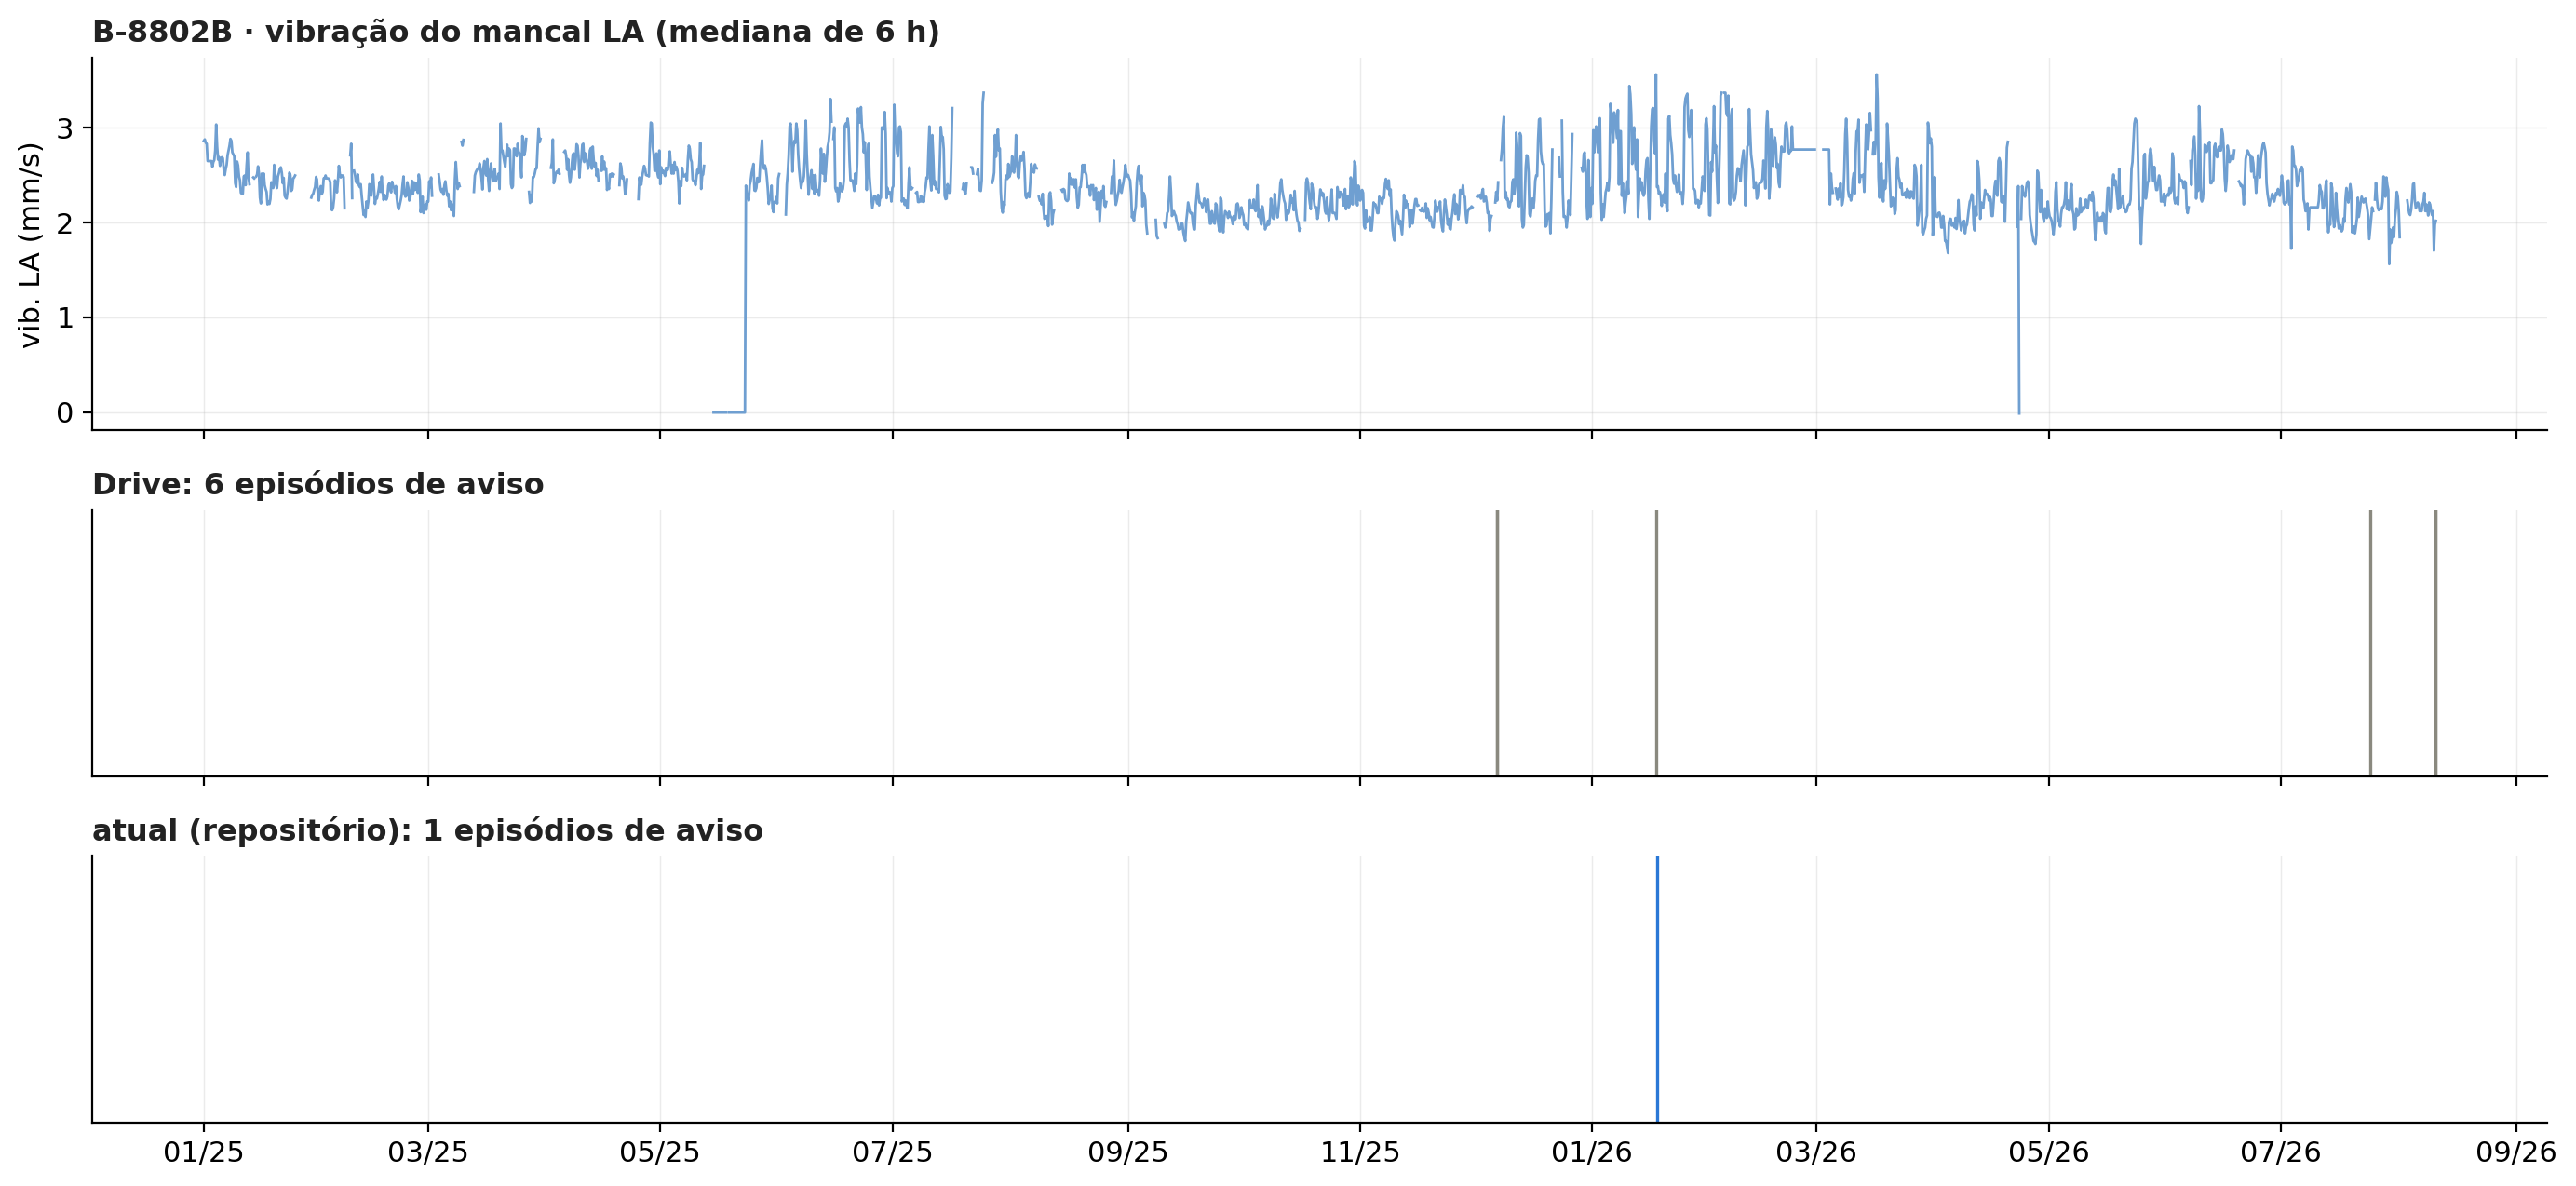

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1, 1]})
pr = si.preprocessar  # só para alinhar o índice
v = raw["Vibração Bomba LA"].where(raw["Pressão Descarga"] > 35).resample("6h").median()
axes[0].plot(v.index, v.values, color="#6f9fd1", lw=1); axes[0].set_ylabel("vib. LA (mm/s)")
estilo(axes[0], "B-8802B · vibração do mancal LA (mediana de 6 h)")
for ax, (n, (_, _, cor)) in zip(axes[1:], VERSOES.items()):
    ep = episodios(res[n]["aviso"].astype(bool))
    for i, f in ep:
        ax.axvspan(i, f + pd.Timedelta("30min"), color=cor, lw=0, alpha=0.9)
        ax.axvline(i, color=cor, lw=1.2)
    ax.set_yticks([]); estilo(ax, f"{n}: {len(ep)} episódios de aviso")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout()

## 3. Os avisos que só a versão do Drive dá

Para cada episódio da versão do Drive que **não** vira aviso na atual: os sensores e o score em relação ao limiar.
São os casos que a regra nova elimina — confira se algum deles parece real.

5 de 6 episódios do Drive não aparecem na versão atual


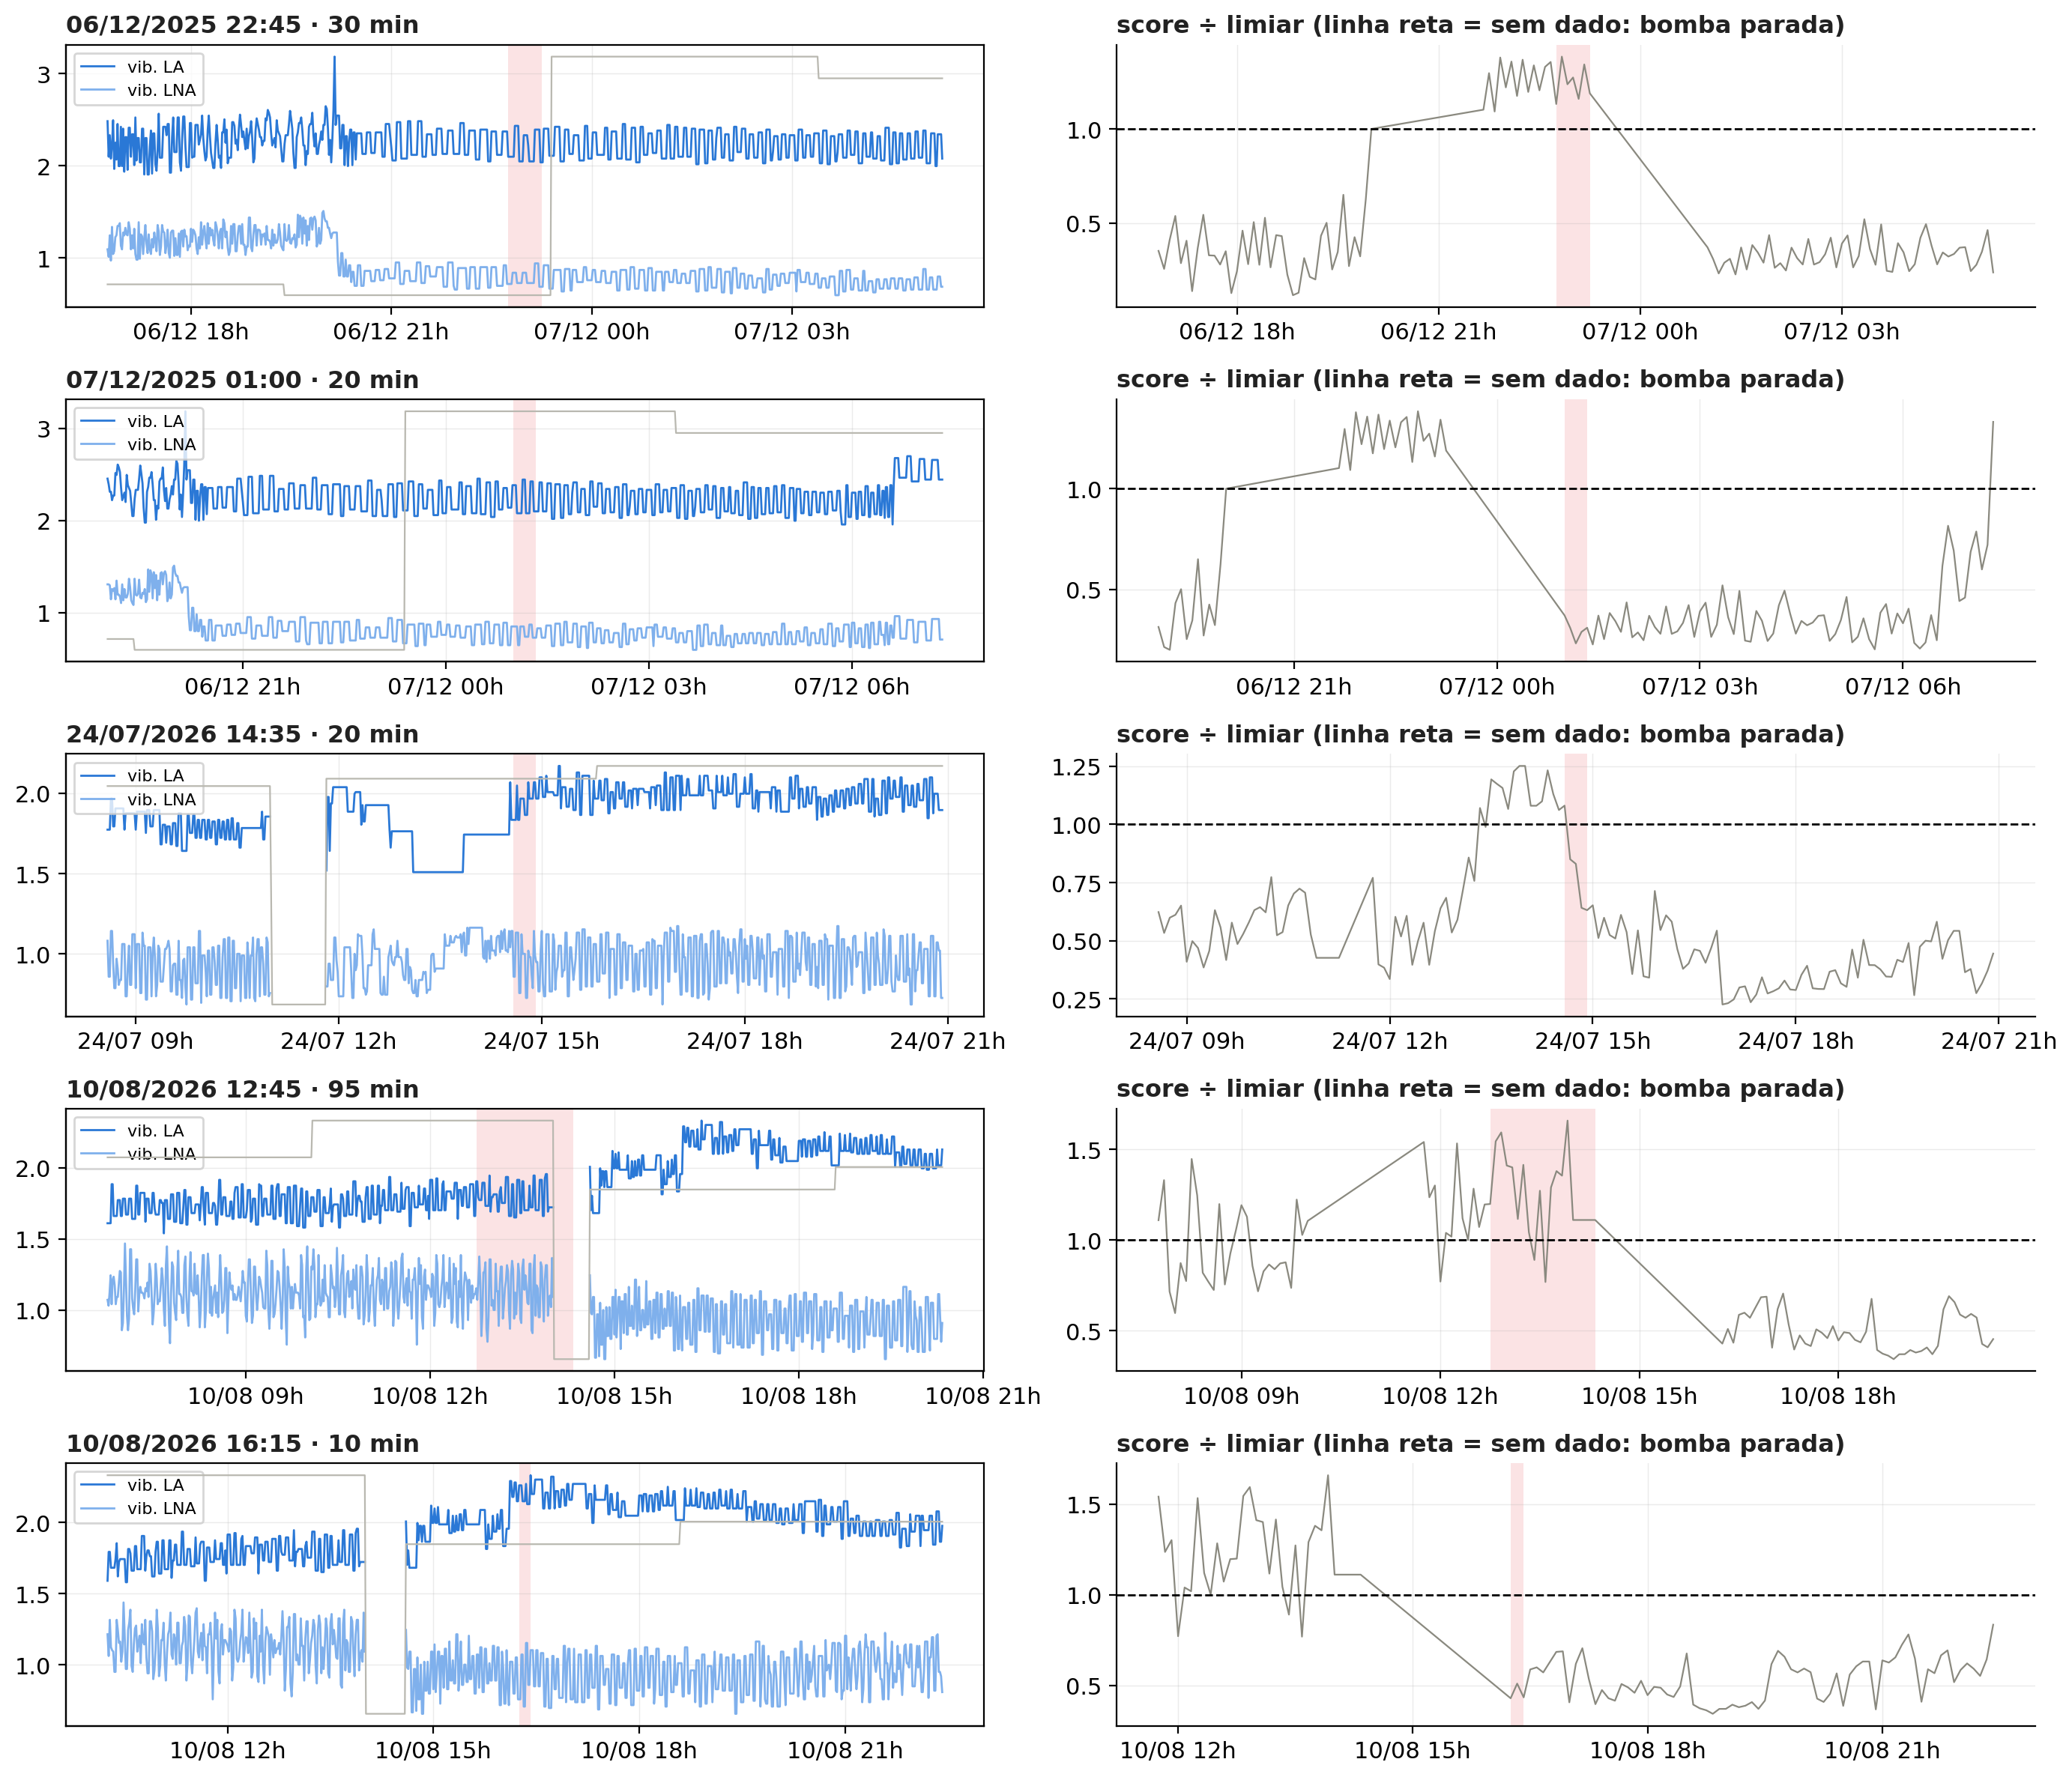

In [5]:
drive_ep = episodios(res["Drive"]["aviso"].astype(bool))
atual = res["atual (repositório)"]["aviso"].astype(bool)
so_drive = [(i, f) for i, f in drive_ep if not atual.loc[i - pd.Timedelta("2h"): f + pd.Timedelta("2h")].any()]
print(f"{len(so_drive)} de {len(drive_ep)} episódios do Drive não aparecem na versão atual")
thr = json.loads((ATUAL_BUNDLE / "alarm.json").read_text())["threshold"]
mostrar = so_drive[:6]
if mostrar:
    fig, axes = plt.subplots(len(mostrar), 2, figsize=(14, 2.4 * len(mostrar)), squeeze=False)
    for k, (i, f) in enumerate(mostrar):
        a, b = i - pd.Timedelta("6h"), f + pd.Timedelta("6h")
        w = raw.loc[a:b]
        ax = axes[k, 0]
        for c, cor in [("Vibração Bomba LA", "#2a78d6"), ("Vibração Bomba LNA", "#7fb0ec")]:
            ax.plot(w.index, w[c].where(w["Pressão Descarga"] > 35), color=cor, lw=1, label=c.replace("Vibração Bomba ", "vib. "))
        ax2 = ax.twinx(); ax2.plot(w.index, w["Pressão Descarga"], color="#b9b8b0", lw=0.8); ax2.set_yticks([])
        ax.axvspan(i, f, color="#e5484d", alpha=0.15, lw=0)
        estilo(ax, f"{i:%d/%m/%Y %H:%M} · {(f - i).total_seconds() / 60:.0f} min"); ax.legend(fontsize=8, loc="upper left")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
        ax = axes[k, 1]
        s = res["Drive"]["reconstruction_error"].loc[a:b] / thr
        ax.plot(s.index, s.values, color="#8a897f", lw=0.8); ax.axhline(1, color="black", ls="--", lw=1)
        ax.axvspan(i, f, color="#e5484d", alpha=0.15, lw=0)
        estilo(ax, "score ÷ limiar (linha reta = sem dado: bomba parada)")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.tight_layout()

**Leitura (versão reconstruída do git):** a regra antiga contava "15 das últimas 20 linhas", e as linhas pulam as
paradas da bomba. Por isso ela juntava leituras de antes e de depois de uma parada:
- **07/12/2025 01:00, 24/07/2026 e 10/08/2026 16:15**: o score está baixo (0,3–0,6 do limiar) no momento do aviso —
  o aviso vem de leituras altas de antes da parada. São **artefatos** da regra antiga; a atual os elimina.
- **06/12/2025 22:45** (30 min) e **10/08/2026 12:45** (95 min, mas só ~40 min de medição real): o score passou do
  limiar de verdade, por pouco tempo. A regra de 1 h os descarta. O de 06/12 coincide com o evento térmico de 03–07/12/2025
  (mancal LNA até 71 °C), que já vimos antes — é o único que **talvez** valesse um aviso.

## 4. Veredito

- **O modelo não muda**; atualizar o Drive é trocar o `simpred_inference.py` e o `alarm.json` do B-8802B-2025
  (e acrescentar `drift_ref.json` / `residual_ref.json` se o monitor de drift for usado).
- **Vale integrar:** em 2025–26 os avisos caem de 6 episódios para 1 (17/01/2026); 3 dos 5 eliminados são artefatos
  de parada da bomba e os outros 2 duram menos de 1 h. Na falha de 2022 a antecedência é a mesma (~50 h). O único custo
  é não avisar eventos curtos como o de 06/12/2025 — que a temperatura, de qualquer forma, não é o modelo que pega
  (o monitor M8 de temperatura cobre isso). A regra de 1 h já está no B-6511502A pelo mesmo motivo.